# How real neurons fire

**Question:** In project 01, a model neuron driven by a constant current fired like clockwork: every run gave exactly the same spike train. How do real neurons in a living brain fire when the same kind of picture appears again and again, and which brain areas respond to it?

**Data:** Neuropixels recordings from mice doing a visual task (Steinmetz, Zatka-Haas, Carandini & Harris, 2019, *Nature*). A picture (a striped grating) appears on the left and/or right screen, and the mouse turns a wheel to bring the picture with the higher contrast to the centre; if there is no picture, it holds the wheel still. Meanwhile, probes record spikes in many brain areas at once. We use the preprocessed version from Neuromatch Academy: spike counts in 10 ms bins, from 0.5 s before to 2 s after the picture appears.

**Tools:** the peri-stimulus time histogram (PSTH), Gerstner et al., *Neuronal Dynamics* (2014), Sect. 7.2.2.

Imports and plot style, the same as in project 01.

In [1]:
from pathlib import Path
import urllib.request

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
BLUE = "#2a78d6"  # data
GRAY = "#52514e"  # reference lines, labels, control condition
ORANGE = "#eb6834"

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

Download the first of the three data files (13 recording sessions, 88 MB) from the Open Science Framework, but only if it is not on disk yet. The data folder is not part of the repository.

In [2]:
data_file = DATA_DIR / "steinmetz_part0.npz"
if not data_file.exists():
    urllib.request.urlretrieve("https://osf.io/agvxh/download", data_file)
print(f"{data_file.name}: {data_file.stat().st_size / 1e6:.0f} MB")

steinmetz_part0.npz: 88 MB


Load all 13 sessions and pick session 0: mouse "Cori", with many neurons in the primary visual cortex. Each session is a dictionary; `spks` holds the spike counts with the shape (neurons, trials, time bins).

In [3]:
sessions = np.load(data_file, allow_pickle=True)["dat"]
s = sessions[0]

spks = s["spks"]          # spike counts: neurons x trials x 10-ms bins
area = s["brain_area"]    # brain area of each neuron
dt = s["bin_size"]        # bin width: 0.01 s
t = np.arange(spks.shape[2]) * dt - s["stim_onset"]  # time relative to picture onset (s)

n_neurons, n_trials, n_bins = spks.shape
print(f"mouse {s['mouse_name']}, {s['date_exp']}: {n_neurons} neurons, {n_trials} trials, "
      f"{n_bins} bins of {dt * 1000:.0f} ms ({t[0]:.1f} to {t[-1] + dt:.1f} s)")

mouse Cori, 2016-12-14: 734 neurons, 214 trials, 250 bins of 10 ms (-0.5 to 2.0 s)


Which brain areas were recorded, and how many neurons each:

In [4]:
areas, counts = np.unique(area, return_counts=True)
for a, c in sorted(zip(areas, counts), key=lambda x: -x[1]):
    print(f"{a:5s} {c:4d}")

VISp   178
LS     139
MOs    113
ACA    109
SUB     75
CA3     68
DG      34
root    18


The trials differ in where a picture appears and how strong its contrast is (0, 25, 50 or 100 %). We split them into two groups: a picture on at least one side, and no picture at all (the control).

In [5]:
picture = (s["contrast_left"] > 0) | (s["contrast_right"] > 0)
no_picture = ~picture
print(f"{picture.sum()} trials with a picture, {no_picture.sum()} trials without")

168 trials with a picture, 46 trials without


The PSTH turns the spike counts of many trials into a firing rate over time (Eq. 7.9):

$$\nu(t) = \frac{1}{K\,\Delta t}\sum_{k=1}^{K} n_k(t)$$

$K$ is the number of trials, $\Delta t$ the bin width, and $n_k(t)$ the number of spikes in trial $k$ in the bin starting at time $t$. A small helper adds up neighbouring 10-ms bins, so that we can use wider bins when a single neuron gives too few spikes.

In [6]:
def rebin(counts, n):
    # Add up n neighbouring bins along the last axis, e.g. n = 5 turns 10-ms bins into 50-ms bins
    n_keep = counts.shape[-1] // n * n
    return counts[..., :n_keep].reshape(*counts.shape[:-1], -1, n).sum(axis=-1)


def psth(counts, bin_width):
    # Time-dependent firing rate (Hz) from spike counts with shape (trials, bins), Eq. (7.9)
    K = counts.shape[0]  # number of trials
    rate = counts.sum(axis=0) / (K * bin_width)  # Eq. (7.9) 
    return rate

## One neuron

We compare each neuron's rate in the 0.5 s before the picture with its rate 0.05 to 0.25 s after, using all trials with a picture. As an example, we pick the neuron in the primary visual cortex (VISp) whose rate rises most, among the neurons that fire less than 5 Hz before the picture (so that single spikes stay visible in the raster plot).

In [7]:
before = (t >= -0.5) & (t < 0)    # 0.5 s before the picture
after = (t >= 0.05) & (t < 0.25)  # first response window after the picture

visp = np.flatnonzero(area == "VISp")
rate_before = spks[visp][:, picture][:, :, before].mean(axis=(1, 2)) / dt  # Hz, per neuron
rate_after = spks[visp][:, picture][:, :, after].mean(axis=(1, 2)) / dt
rise = rate_after - rate_before
print(f"{np.sum(rise > 2)} of {len(visp)} VISp neurons rise by more than 2 Hz")

quiet = rate_before < 5
i = np.argmax(np.where(quiet, rise, -np.inf))  # largest rise among the quiet neurons
best = visp[i]
print(f"example: neuron {best}, {rate_before[i]:.1f} Hz before, {rate_after[i]:.1f} Hz after the picture")

31 of 178 VISp neurons rise by more than 2 Hz
example: neuron 419, 2.7 Hz before, 17.5 Hz after the picture


Raster plot (one row per trial, one dash per spike) and PSTH with 50-ms bins for this neuron. The dashed line marks the moment the picture appears.

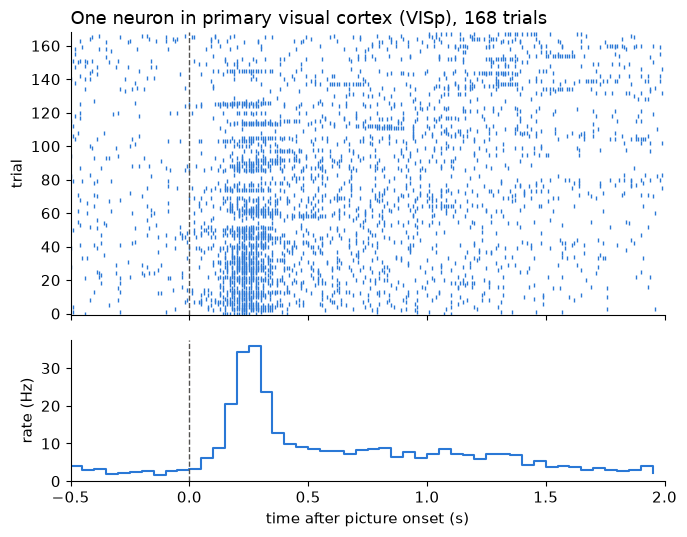

In [8]:
x = spks[best][picture]  # trials x bins
w = 5                    # 5 x 10 ms = 50-ms bins for the PSTH

fig, (ax_r, ax_p) = plt.subplots(2, 1, figsize=(7, 5.5), sharex=True,
                                 gridspec_kw={"height_ratios": [2, 1]})
trial_idx, bin_idx = np.nonzero(x)
ax_r.plot(t[bin_idx], trial_idx, "|", color=BLUE, ms=3, mew=1)
ax_r.axvline(0, color=GRAY, lw=1, ls="--")
ax_r.set(ylabel="trial", ylim=(-1, len(x)))
ax_r.set_title(f"One neuron in primary visual cortex (VISp), {len(x)} trials", loc="left")

ax_p.step(t[::w], psth(rebin(x, w), w * dt), where="post", color=BLUE, lw=1.5)
ax_p.axvline(0, color=GRAY, lw=1, ls="--")
ax_p.set(xlabel="time after picture onset (s)", ylabel="rate (Hz)", xlim=(t[0], t[-1] + dt), ylim=(0, None))

fig.tight_layout()
fig.savefig(FIG_DIR / "visp_neuron_raster_psth.png", dpi=150)
plt.show()

## Which brain areas respond to the picture?

Now we average over all neurons of an area: every neuron-trial pair counts as one row, so the PSTH gives the mean rate per neuron. We show the change from the rate before the picture, for trials with a picture (blue) and without (gray), in all areas with at least 50 recorded neurons. Bins are 20 ms wide.

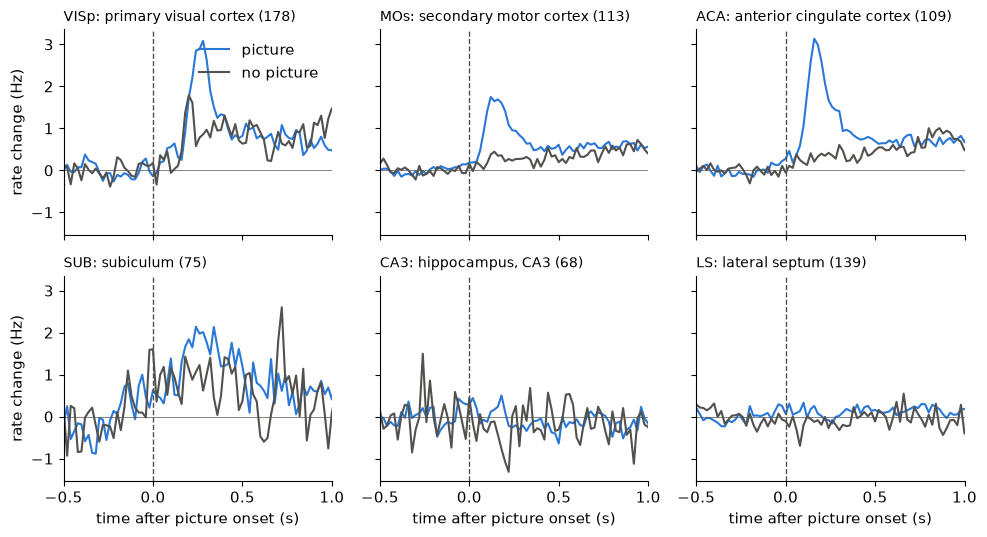

In [9]:
names = {"VISp": "primary visual cortex", "MOs": "secondary motor cortex",
         "ACA": "anterior cingulate cortex", "SUB": "subiculum",
         "CA3": "hippocampus, CA3", "LS": "lateral septum"}
big_areas = [a for a in names if np.sum(area == a) >= 50]
w = 2  # 20-ms bins

fig, axes = plt.subplots(2, 3, figsize=(10, 5.5), sharex=True, sharey=True)
for ax, a in zip(axes.flat, big_areas):
    m = area == a
    for trials, color, label in [(picture, BLUE, "picture"), (no_picture, GRAY, "no picture")]:
        rows = rebin(spks[m][:, trials], w).reshape(-1, n_bins // w)  # (neurons * trials) x bins
        rate = psth(rows, w * dt)
        change = rate - rate[t[::w] < 0].mean()
        ax.plot(t[::w], change, color=color, lw=1.5, label=label)
    ax.axvline(0, color=GRAY, lw=1, ls="--")
    ax.axhline(0, color=GRAY, lw=0.5)
    ax.set_title(f"{a}: {names[a]} ({m.sum()})", loc="left", fontsize=10)

for ax in axes[1]:
    ax.set_xlabel("time after picture onset (s)")
for ax in axes[:, 0]:
    ax.set_ylabel("rate change (Hz)")
axes[0, 0].legend(frameon=False, loc="upper right")
axes[0, 0].set_xlim(-0.5, 1.0)

fig.tight_layout()
fig.savefig(FIG_DIR / "areas_psth.png", dpi=150)
plt.show()

The same in numbers: the mean rate change in the first response window (0.05 to 0.25 s after the picture), per area.

In [10]:
print(f"{'area':5s} {'before (Hz)':>12s} {'picture':>9s} {'no picture':>11s}")
for a in big_areas:
    m = area == a
    base = spks[m][:, :, before].mean() / dt
    d_pic = spks[m][:, picture][:, :, after].mean() / dt - spks[m][:, picture][:, :, before].mean() / dt
    d_no = spks[m][:, no_picture][:, :, after].mean() / dt - spks[m][:, no_picture][:, :, before].mean() / dt
    print(f"{a:5s} {base:12.1f} {d_pic:+9.1f} {d_no:+11.1f}")

area   before (Hz)   picture  no picture
VISp           3.1      +0.9        +0.7
MOs            1.1      +1.3        +0.2
ACA            1.4      +1.8        +0.3
SUB            5.9      +1.1        +0.9
CA3            3.9      +0.1        -0.5
LS             3.4      +0.1        -0.2


When does the mouse start to turn the wheel? The median reaction time in trials with a picture where the mouse moved:

In [11]:
moved = s["response"] != 0
reaction_ms = s["reaction_time"][:, 0]  # time from picture onset to the first wheel movement (ms)
print(f"median reaction time: {np.median(reaction_ms[picture & moved]):.0f} ms "
      f"({np.sum(picture & moved)} trials)")

median reaction time: 210 ms (128 trials)


**Result.** The primary visual cortex (VISp), the secondary motor cortex (MOs) and the anterior cingulate cortex (ACA) respond to the picture: their mean rate rises clearly above the trials without a picture. The hippocampus (CA3) and the lateral septum (LS) do not respond, and the subiculum (SUB) changes in both conditions alike. That VISp responds is expected. The response of MOs fits with the mouse turning the wheel, but its peak (about 0.12 to 0.15 s) comes before the wheel starts to move in most trials (median 0.21 s), so it looks more like preparing or choosing the movement than moving. What ACA does here, this analysis cannot tell. One open observation: VISp also rises a little in trials without a picture (about +1.8 Hz at 0.2 s), and we do not know why. The gray curves are noisier than the blue ones partly because they average over 46 instead of 168 trials.

## Part 2: Clockwork or dice?

In project 01, the LIF neuron with a constant current fired like clockwork. The Fano factor (Sect. 7.2.1, Eq. 7.2) measures how much the spike count $n$ in a time window varies from trial to trial:

$$F = \frac{\langle(\Delta n)^2\rangle}{\langle n\rangle} = \frac{\text{variance of the count}}{\text{mean count}}$$

Clockwork gives the same count every time, so $F = 0$. A Poisson process, where every spike is an independent throw of the dice, gives $F = 1$ (Sect. 7.2.1).

We count spikes in the 0.5 s before the picture appears. In this window nothing is shown yet, in any trial, so all 214 trials are the same condition. Neurons with less than one spike per window on average (below 2 Hz) are left out, because their Fano factor is too uncertain.

In [12]:
window = (t >= -0.5) & (t < 0)  # 0.5 s before the picture
T_window = 0.5                  # window length (s)

n = spks[:, :, window].sum(axis=2).astype(float)  # spike counts: neurons x trials
mean_n = n.mean(axis=1)
var_n = n.var(axis=1)           # <(n - <n>)^2>, averaged over trials as in Eq. (7.2)

active = mean_n >= 1
fano = var_n[active] / mean_n[active]
print(f"{active.sum()} of {n_neurons} neurons fire at least 2 Hz before the picture")
print(f"Fano factor: median {np.median(fano):.2f}, middle half {np.percentile(fano, 25):.2f} to "
      f"{np.percentile(fano, 75):.2f}; {np.mean(fano > 1):.0%} of the neurons have F > 1")

304 of 734 neurons fire at least 2 Hz before the picture
Fano factor: median 1.87, middle half 1.38 to 2.71; 88% of the neurons have F > 1


The same per brain area:

In [13]:
area_active = area[active]
for a in big_areas:
    m = area_active == a
    print(f"{a:5s} {m.sum():3d} neurons, median F = {np.median(fano[m]):.2f}")

VISp   67 neurons, median F = 2.33
MOs    19 neurons, median F = 2.39
ACA    23 neurons, median F = 2.30
SUB    56 neurons, median F = 1.95
CA3    39 neurons, median F = 1.89
LS     74 neurons, median F = 1.44


For comparison, the LIF neuron of project 01, with the same parameters and the same Euler method. It runs for 214 × 0.5 s without a break, and we cut its spike train into 214 windows of 0.5 s, like the trials. Because the windows start at different points of its firing rhythm, the count can still differ by one spike.

In [14]:
# LIF neuron of project 01 (units: mV, ms, MOhm, nA)
u_rest, theta, u_reset = -70.0, -50.0, -70.0
R, tau_m = 10.0, 10.0


def simulate_lif(I, T, dt=0.1):
    # Same model and Euler step as in project 01 (Eq. 1.5, threshold, reset), but only the spike times (ms) are kept
    u = u_rest
    spike_times = []
    for k in range(int(round(T / dt))):
        u += ((-(u - u_rest) + R * I) / tau_m) * dt
        if u >= theta:
            spike_times.append((k + 1) * dt)
            u = u_reset
    return np.array(spike_times)


n_trials_lif = n_trials
lif = {}
for I in [2.01, 2.1, 3.0]:  # input currents (nA): about 19, 33 and 91 Hz in project 01
    spike_times = simulate_lif(I, n_trials_lif * T_window * 1000)
    counts = np.histogram(spike_times, bins=np.arange(n_trials_lif + 1) * T_window * 1000)[0]
    lif[I] = {"spikes": spike_times, "counts": counts, "fano": counts.var() / counts.mean()}
    print(f"LIF {I:g} nA: {counts.mean() / T_window:.0f} Hz, counts {counts.min()} to {counts.max()}, "
          f"F = {lif[I]['fano']:.3f}")

LIF 2.01 nA: 19 Hz, counts 9 to 10, F = 0.026
LIF 2.1 nA: 33 Hz, counts 16 to 17, F = 0.015
LIF 3 nA: 91 Hz, counts 45 to 46, F = 0.005


Main figure of part 2. Left: the LIF neuron at 2.1 nA (about 33 Hz) and the VISp neuron whose rate before the picture is closest to it, each in 30 windows of 0.5 s. Right: the Fano factors of all active neurons, with the LIF values and the Poisson value $F = 1$.

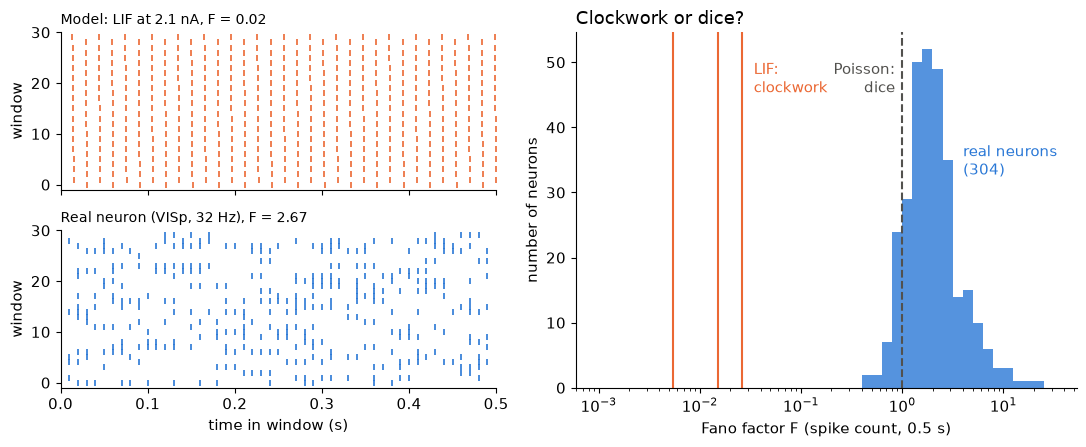

In [15]:
rate_before = mean_n / T_window  # Hz, all neurons
real = visp[np.argmin(np.abs(rate_before[visp] - 33))]  # VISp neuron closest to 33 Hz
n_show = 30

fig = plt.figure(figsize=(11, 4.6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1.15])
ax_lif, ax_real = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0])
ax_f = fig.add_subplot(gs[:, 1])

# left top: LIF, spike times inside each 0.5-s window
sp = lif[2.1]["spikes"] / 1000  # s
for k in range(n_show):
    inside = sp[(sp >= k * T_window) & (sp < (k + 1) * T_window)] - k * T_window
    ax_lif.plot(inside, np.full_like(inside, k), "|", color=ORANGE, ms=4, mew=1.2)
ax_lif.set_title(f"Model: LIF at 2.1 nA, F = {lif[2.1]['fano']:.2f}", loc="left", fontsize=10)

# left bottom: real neuron, same window before the picture
x = spks[real][:n_show][:, window]
trial_idx, bin_idx = np.nonzero(x)
ax_real.plot(t[window][bin_idx] + T_window, trial_idx, "|", color=BLUE, ms=4, mew=1.2)
ax_real.set_title(f"Real neuron (VISp, {rate_before[real]:.0f} Hz), F = {var_n[real] / mean_n[real]:.2f}",
                  loc="left", fontsize=10)
for ax in (ax_lif, ax_real):
    ax.set(xlim=(0, T_window), ylim=(-1, n_show), ylabel="window")
ax_real.set_xlabel("time in window (s)")
ax_lif.set_xticklabels([])

# right: histogram of Fano factors (log axis), LIF and Poisson for reference
bins = np.logspace(-3, 1.5, 46)
ax_f.hist(fano, bins=bins, color=BLUE, alpha=0.8)
for I in lif:
    ax_f.axvline(lif[I]["fano"], color=ORANGE, lw=1.5)
ax_f.axvline(1, color=GRAY, lw=1.5, ls="--")
ax_f.text(max(v["fano"] for v in lif.values()) * 1.3, ax_f.get_ylim()[1] * 0.92, "LIF:\nclockwork", color=ORANGE, va="top")
ax_f.text(0.85, ax_f.get_ylim()[1] * 0.92, "Poisson:\ndice", color=GRAY, va="top", ha="right")
ax_f.set_xscale("log")
ax_f.set(xlabel="Fano factor F (spike count, 0.5 s)", ylabel="number of neurons")
ax_f.set_title("Clockwork or dice?", loc="left")
ax_f.text(4, ax_f.get_ylim()[1] * 0.6, f"real neurons\n({len(fano)})", color=BLUE)

fig.tight_layout()
fig.savefig(FIG_DIR / "fano_clockwork_or_dice.png", dpi=150)
plt.show()

Why are real neurons even more variable than dice? If the rate itself changes from trial to trial (for example because the mouse is more or less engaged), the counts vary more than a Poisson process with one fixed rate would allow. Then the Fano factor should grow with the window length, because slow changes of the rate add up over longer windows. A quick check with shorter windows:

In [16]:
for T_w in [0.1, 0.25, 0.5]:
    w_mask = (t >= -T_w) & (t < 0)
    counts_w = spks[:, :, w_mask].sum(axis=2).astype(float)
    mean_w = counts_w.mean(axis=1)
    keep = mean_w >= 2 * T_w  # same rule as above: at least 2 Hz
    print(f"window {T_w:.2f} s: median F = {np.median(counts_w[keep].var(axis=1) / mean_w[keep]):.2f} "
          f"({keep.sum()} neurons)")

window 0.10 s: median F = 1.31 (306 neurons)
window 0.25 s: median F = 1.60 (301 neurons)
window 0.50 s: median F = 1.87 (304 neurons)


**Result.** The LIF neuron of project 01 fires like clockwork: in every 0.5-s window its spikes come at the same regular intervals, and the count changes by at most one spike, so its Fano factor is practically zero (0.005 to 0.026, depending on the current). The real neurons are irregular: the VISp neuron with almost the same rate (32 Hz) has F = 2.67, and over all 304 active neurons the median is 1.87, with 88 % above 1. Real neurons are therefore not only far from clockwork; they are even more variable than a Poisson process with a fixed rate. A likely reason is that the rate itself changes from trial to trial, for example with the mouse's engagement. The Fano factor grows with the window length (1.31 at 0.1 s, 1.87 at 0.5 s), as slow changes of the rate would predict; this fits that explanation but does not prove it.